# Wasserstein Barycenters

We are given $n$ input histograms (probability vectors)
$$
a^{(j)} \in \Delta_m,\qquad j=1,\dots,n,
$$
and barycenter weights
$$
\lambda \in \Delta_n,\qquad \lambda_j>0,\ \sum_{j=1}^n \lambda_j = 1,
$$
together with a cost matrix
$$
C \in \mathbb{R}^{m\times m}.
$$
The entropic Wasserstein barycenter problem is
$$
\min_{b\in \Delta_m}\ \sum_{j=1}^n \lambda_j, W_\varepsilon(a^{(j)}, b).
$$
Here $W_\varepsilon(a,b)$ denotes the entropically regularized OT value:
$$
W_\varepsilon(a^{(j)},b)
\;:=\;
\min_{\pi\in\mathbb{R}_+^{m\times m}}
\left\{
\langle C,\pi\rangle
\;+\;
\varepsilon \sum_{i,k=1}^m \pi_{ik}\big(\log \pi_{ik}-1\big)
\;:\;
\pi\mathbf{1}=a^{(j)},\ \pi^\top\mathbf{1}=b
\right\}.
$$

The (unregularized) Wasserstein barycenter is defined by the same outer minimization over $b\in\Delta_m$, but using the *standard* OT cost (no entropic term). Concretely, let
$$
W(a^{(j)},b)\;:=\;\min_{\pi\in\mathbb{R}_+^{m\times m}}
\left\{\langle C,\pi\rangle\;:\;\pi\mathbf{1}=a^{(j)},\ \pi^\top\mathbf{1}=b\right\},
$$
i.e., the Kantorovich optimal transport value with cost matrix $C$. Then the Wasserstein barycenter problem is
$$
\min_{b\in\Delta_m}\ \sum_{j=1}^n \lambda_j\, W(a^{(j)}, b).
$$

### Dual form of entropic OT (one pair $(a, b)$)

For entropic OT between $a^{(j)}$ and $b$, one convenient dual form is
$$
W_\varepsilon(a^{(j)},b) = 
   \max_{f,g\in \mathbb{R}^m}
   \langle f, a^{(j)} \rangle + \langle g, b \rangle
   - \varepsilon \sum_{i,k}^{m} \exp \left(\frac{f_i + g_k - C_{ik}}{\varepsilon} \right),
$$
where $f$ and $g$ are the dual potentials.

For the barycenter objective this gives
$$
\min_{b \in \Delta_m}
   \sum_{j=1}^n \lambda_j
      \max_{f^{(j)},g^{(j)} \in \mathbb{R}^m}
   \left[
      \langle f^{(j)}, a^{(j)} \rangle + \langle g^{(j)}, b \rangle
      - \varepsilon \sum_{i,k}^{m} \exp \left( \frac{f^{(j)}_i+g^{(j)}_k-C_{ik}}{\varepsilon} \right)
   \right].
$$

Under standard convexity/concavity conditions (the entropic regularization makes things well-behaved), we can swap $\min_b$ and $\max$ (min–max theorem) and isolate the $b$-dependent term:
$$
\max_{{f^{(j)}, g^{(j)}}}
\left\{
   \sum_{j=1}^n \lambda_j \langle f^{(j)}, a^{(j)}\rangle
      + \min_{b\in\Delta_m} \left\langle \sum_{j=1}^n \lambda_j g^{(j)},\ b \right\rangle
      - \varepsilon\sum_{j=1}^n \lambda_j
         \sum_{i,k}^{m} \exp \left( \frac{f^{(j)}_i + g^{(j)}_k - C_{ik}}{\varepsilon} \right)
\right\}.
$$

---

At this point the barycenter variable $b$ only appears through the linear simplex minimization
$$
\min_{b\in\Delta_m}\left\langle \sum_{j=1}^n \lambda_j g^{(j)},\ b \right\rangle.
$$
A necessary and sufficient stationarity condition for this term to be well-posed (i.e., not forcing $b$ to collapse onto a simplex vertex) is that its linear coefficient vanishes:
$$
\sum_{j=1}^n \lambda_j g^{(j)} = 0.
$$
Imposing this optimality condition eliminates $b$ from the min–max expression, and the barycenter problem becomes the constrained dual optimization
$$
\max_{\{f^{(j)},g^{(j)}\}_{j=1}^n}
\left\{
   \sum_{j=1}^n \lambda_j \langle f^{(j)}, a^{(j)}\rangle
   \;-\;
   \varepsilon\sum_{j=1}^n \lambda_j
   \sum_{i,k=1}^{m} \exp\!\left(\frac{f^{(j)}_i + g^{(j)}_k - C_{ik}}{\varepsilon}\right)
\right\}
\quad \text{s.t.}\quad
\sum_{j=1}^n \lambda_j g^{(j)} = 0.
$$
Equivalently, in log-domain Sinkhorn variables $f^{(j)}=\varepsilon\log u^{(j)}$ and $g^{(j)}=\varepsilon\log v^{(j)}$, the stationarity condition reads
$$
\sum_{j=1}^n \lambda_j \log v^{(j)} = 0
\qquad \Longleftrightarrow \qquad
\prod_{j=1}^n \big(v^{(j)}\big)^{\lambda_j} = \mathbf{1}.
$$

---

### Log-domain Sinkhorn updates for each $(a^{(j)}, b)$

Define the Gibbs kernel
$$
   K = \exp \left( - \frac{C}{\varepsilon} \right) .
$$
For a fixed $b$, the entropic OT coupling for each $j$ has the scaled form
$$
   P^{(j)} = \operatorname{diag}(u^{(j)})  K  \operatorname{diag}(v^{(j)}) ,
$$
with marginal constraints
$$
P^{(j)} \mathbf{1} = a^{(j)} , \qquad (P^{(j)})^T \mathbf{1} = b.
$$
In the **log domain**, the usual Sinkhorn updates become **log-sum-exp** updates for the potentials:

**(1) Update $f^{(j)}$ given $g^{(j)}$:**
$$
f^{(j)}_i \leftarrow
   \varepsilon \log a^{(j)}_i
   - \varepsilon \log \left( \sum_{k=1}^m
      \exp \left(
         \frac{g^{(j)}_k - C_{ik}}{\varepsilon}
      \right)
   \right) .
$$

**(2) Update $g^{(j)}$ given $f^{(j)}$ and $b$:**
$$
g^{(j)}_k \leftarrow
   \varepsilon \log b
   - \varepsilon \log \left(\sum_{i=1}^m
   \exp \left(
         \frac{f^{(j)}_i - C_{ik}}{\varepsilon}
      \right)
   \right) .
$$

These are exactly the “stable” log-domain versions of
$$
u^{(j)} \leftarrow \frac{a^{(j)}}{K v^{(j)}},
\qquad
v^{(j)} \leftarrow \frac{b}{K^T u^{(j)}}.
$$

### Deriving the barycenter update $b$ (the geometric mean step)

From the standard Sinkhorn relation (second marginal constraint) we have, for each $j$,
$$
b = v^{(j)} \odot ( K^T u^{(j)} ) ,
$$
so in log-domain:
$$
\log b = \log v^{(j)} + \log ( K^T u^{(j)} ) .
$$

Now take the weighted average over $j$ with weights $\lambda_j$:
$$
\log b = 
   \sum_{j=1}^n \lambda_j \log v^{(j)}
   + \sum_{j=1}^n \lambda_j \log( K^T u^{(j)} ) .
$$

Using the gauge condition from above,
$$
\sum_{j=1}^n \lambda_j \log v^{(j)} = 0 ,
$$
we obtain the barycenter update
$$
\boxed{
   \log b = 
   \sum_{j=1}^n \lambda_j \log( K^T u^{(j)} )
}
\qquad\Longleftrightarrow\qquad
\boxed{
   b \; \propto \; \prod_{j=1}^{n} \exp \left(
            K^T u^{(j)} \right)^{\lambda_j} .
}
$$

So $b$ is the **weighted geometric mean** of the vectors $(K^T u^{(j)})$.

In practice we finally renormalize:
$$
b \leftarrow \frac{b}{\langle b , \mathbf{1} \rangle}.
$$

---

### Summary: one stable log-domain barycenter iteration

Given current potentials $f^{(j)}, g^{(j)}$:

1. For each $j$, update $f^{(j)}$ by log-sum-exp using $g^{(j)}$ and $a^{(j)}$.
   $$
   f^{(j)}_i \leftarrow
      \varepsilon \log a^{(j)}_i
      - \varepsilon \log \left( \sum_{k=1}^m
         \exp \left(
            \frac{g^{(j)}_k - C_{ik}}{\varepsilon}
         \right)
      \right) .
   $$

2. Compute $\log(K^T u^{(j)})$ in a stable way:
   $$
   \log(K^T u^{(j)})_k = 
      \log \left(
         \sum_{i=1}^m \exp \left( \frac{f^{(j)}_i - C_{ik}}{\varepsilon} \right)
         \right).
   $$

3. Update barycenter:
   <!-- $$
   \log b \leftarrow
      \sum_{j=1}^n \lambda_j \log(K^T u^{(j)}),
   \qquad
   b \leftarrow \frac{\exp(\log b)}{\langle \exp(\log b),\mathbf{1}\rangle}.
   $$ -->
   $$
   \log b \leftarrow
      \sum_{j=1}^n \lambda_j \log(K^T u^{(j)}) ,
   \qquad
   b \leftarrow \operatorname{Normalize} \left( \exp(\log b) \right).
   $$

4. For each $j$, update $g^{(j)}$ using the new $b$:
   $$
   g^{(j)}_k
   \leftarrow
      \varepsilon \log b
      - \varepsilon \log \left(
         \sum_{i=1}^m \exp \left(
               \frac{f^{(j)}_i - C_{ik}}{\varepsilon}
            \right)
         \right).
   $$

This works because we are doing **block coordinate ascent on the concave dual** (exact maximizers in $f^{(j)}$ and $g^{(j)}$ given the other blocks), combined with the barycenter block update that enforces the shared second marginal consistently across all $j$ via the geometric-mean formula.

---

In [ ]:
from jax import config
config.update('jax_enable_x64', True)

import os
import numpy as np
import matplotlib.pyplot as plt
import jax.numpy as jnp
from jax import lax
from jax import jit
from jax.scipy.special import logsumexp
from itertools import islice
from typing import Literal

import ot

from uot.utils import costs
from uot.utils.costs import cost_euclid_squared
from uot.problems.generators.toy_barycenter_generator import (
    ToyBarycenterGenerator,
    FixedListSelector,
)
from uot.data.dataset_loader import load_image_as_binary_grid
from uot.data.measure import DiscreteMeasure
from uot.solvers.pdlp_barycenter import PDLPBarycenterSolver

# --- Matplotlib defaults for consistent plots ---
plt.rcParams.update({
    'figure.dpi': 110,
    'savefig.dpi': 110,
    'image.cmap': 'Greys',
    'image.interpolation': 'nearest',
})


In [2]:
TOY_SHAPES = [
    'Ring',
    'GMM',
    'Crescent',
    'Plus',
    'Diamond',
    'Square',
    'Two Squares',
    'Checker',
    'Star',
]

ToyShape = Literal[*TOY_SHAPES]

print('Available toy shapes:')
for name in TOY_SHAPES:
    print(' -', name)


Available toy shapes:
 - Ring
 - GMM
 - Crescent
 - Plus
 - Diamond
 - Square
 - Two Squares
 - Checker
 - Star


## Toy shapes list

Below is the list of available toy shapes you can use.
Pick any subset in `toy_shapes` or `FixedListSelector(...)`.


In [20]:
n_points = 40
grid_shape = (n_points, n_points)

toy_shapes: tuple[ToyShape, ...] = (
    'Plus', 'Diamond', 'Ring'
)
num_marginals = len(toy_shapes)

gen = ToyBarycenterGenerator(
    selector=FixedListSelector(toy_shapes),
    n_points=n_points,
    cost_fn=costs.cost_euclid_squared,
    num_datasets=1,
    measure_mode='discrete',
)

problems = list(gen.generate(num_marginals=num_marginals))
problem = problems[0]

## Toy barycenter setup

We use `ToyBarycenterGenerator` from the `uot-bench` library (in development).
It creates synthetic marginals from the chosen shapes and a grid discretization
(`n_points` and `cell_discretization`) that you can change here.


## Shared support + reshaping

You can change the `lambdas` array here if you want different barycenter weights.
All marginals share the same support, so we read the `(N, d)` support once from the
first measure, stack weights into a `(M, N)` array for the solvers, and reshape each
weight vector into a 2D grid for plotting.


In [21]:
measures = problem.get_marginals()
lambdas = np.asarray((1/3, 1/3, 1/3))

support, w0 = measures[0].to_discrete(include_zeros=True)
meas_array = np.stack(
    [np.asarray(w0).reshape(-1)] +
    [np.asarray(m.to_discrete(include_zeros=True)[1]).reshape(-1) for m in measures[1:]],
    axis=0,
)

cost = cost_euclid_squared(support, support)

grid_shape = (gen.n_points, gen.n_points)
measure_fields = [np.asarray(w).reshape(grid_shape) for w in meas_array]


## Barycenter solvers

We define a log-domain Sinkhorn barycenter with a marginal-error stopping criterion,
then compare it against POT's Sinkhorn and POT LP barycenters and the PDLP solver.


In [ ]:
@jit(static_argnames=[
    'reg',
    'maxiter',
    'return_diagnostics',
])
def barycenter_sinkhorn(
        measures: jnp.ndarray,
        cost: jnp.ndarray,
        lambdas: jnp.ndarray,
        reg: float = 1e-3,
        tol: float = 1e-4,
        maxiter: int = 100,
        return_diagnostics: bool = False,
        error_check_every: int = 20,
):
    lam = (lambdas / lambdas.sum())[:, None]   # (J,1)
    # clip measures for log computations to be a little bit safer in practice
    log_measures = jnp.log(jnp.maximum(measures, 1e-30))
    lnb = jnp.zeros_like(measures[0])
    lnK = -cost / reg

    def cond_fn(state):
        i, lnus, lnvs, lnb, err, errors = state
        return jnp.logical_and(i < maxiter, err > tol)

    def body_fn(state):
        i, lnus, lnvs, lnb, err, errors = state

        # update each f^j
        ln_Kv = logsumexp(
            lnvs[:, None, :] + lnK[None, :, :],
            axis=2,
        )
        lnus = log_measures - ln_Kv
        # compute log(K^T u^j) in a stable way
        ln_Ktu = logsumexp(
            lnus[:, :, None] + lnK[None, :, :],
            axis=1,
        )
        # update barycenter log(b)
        lnb = jnp.sum(lam * ln_Ktu, axis=0)
        lnb = lnb - logsumexp(lnb)   # now renormalize
        # update each g^j
        lnvs = lnb[None, :] - ln_Ktu

        def compute_err(_):
            new_err, _details = marginal_error_from_log(log_measures,
                                                        lnK, lnus, lnvs, lnb)
            return new_err
        err = lax.cond(
            (i % error_check_every) == 0,
            compute_err,
            lambda _: err,
            operand=None,
        )
        errors = errors.at[i].set(err)
        return (i+1, lnus, lnvs, lnb, err, errors)

    lnus = jnp.zeros_like(measures)
    lnvs = jnp.zeros_like(measures)
    errors = jnp.full((maxiter,), jnp.nan)
    err0 = jnp.asarray(jnp.inf)
    init_state = (jnp.asarray(0), lnus, lnvs, lnb, err0, errors)
    final_state = lax.while_loop(cond_fn, body_fn, init_state)
    iterations, lnus, lnvs, lnb, err, errors = final_state
    b = jnp.exp(lnb)
    b /= b.sum()
    diagnostics = {
            'iterations': iterations,
            'error': err,
            **({
                'ln_u': lnus,
                'ln_v': lnvs,
                'ln_b': lnb,
                'errors': errors,
                } if return_diagnostics else {}),
            }
    return b, diagnostics


def marginal_error_from_log(
    log_measures: jnp.ndarray,  # (J, N) = log(a_j)
    lnK: jnp.ndarray,           # (N, N) = -C/reg
    lnus: jnp.ndarray,          # (J, N) = log(u_j)
    lnvs: jnp.ndarray,          # (J, N) = log(v_j)
    lnb: jnp.ndarray,           # (N,)   = log(b)
    eps: float = 1e-30,
):
    # ln(K v_j) and ln(K^T u_j)
    lnKv = logsumexp(lnvs[:, None, :] + lnK[None, :, :], axis=2)    # (J, N)
    lnKtu = logsumexp(lnus[:, :, None] + lnK[None, :, :], axis=1)   # (J, N)
    # implied marginals in normal domain
    a_hat = jnp.exp(lnus + lnKv)                 # (J, N) should match exp(log_measures)
    b_hat = jnp.exp(lnvs + lnKtu)                # (J, N) should match exp(lnb)[None,:]
    a = jnp.exp(log_measures)                    # (J, N)
    b = jnp.exp(lnb)                             # (N,)
    # L2 errors per measure
    err_a_per_j = jnp.sum(jnp.power(a_hat - a, 2), axis=1)           # (J,)
    err_b_per_j = jnp.sum(jnp.power(b_hat - b[None, :], 2), axis=1)  # (J,)
    err_a = jnp.max(err_a_per_j)
    err_b = jnp.max(err_b_per_j)
    err = jnp.maximum(err_a, err_b)
    return err, {"err_a": err_a, "err_b": err_b}

In [23]:
measures_arr = jnp.asarray(meas_array)
lambdas_arr = jnp.asarray(lambdas)
cost_arr = jnp.asarray(cost)

bary_weights, diagnostics = barycenter_sinkhorn(
    measures_arr,
    cost_arr,
    lambdas_arr,
    reg=1e-3,
    maxiter=100,
    tol=1e-4,
)

bary_sinkhorn_field = np.asarray(bary_weights).reshape(grid_shape)


In [24]:
bary_sinkhorn_pot = ot.barycenter(meas_array.T, cost,
                                  weights=np.asarray(lambdas_arr),
                                  reg=1e-3)

bary_sinkhorn_pot_field = np.asarray(bary_sinkhorn_pot).reshape(grid_shape)

In [25]:
bary_lp = ot.lp.barycenter(meas_array.T, cost, weights=np.asarray(lambdas_arr))

bary_lp_field = np.asarray(bary_lp).reshape(grid_shape)

In [36]:
marginals = [
    DiscreteMeasure(points=support, weights=meas_array[i], name=f'measure_{i+1}')
    for i in range(meas_array.shape[0])
]

pdlp_solver = PDLPBarycenterSolver()
result_pdlp = pdlp_solver.solve(
    marginals=marginals,
    costs=[cost],
    weights=lambdas,
    reg=5e-1,
    maxiter=2000,
    tol=1e-4,
)

b_pdlp = np.asarray(result_pdlp['barycenter'])
print(f"PDLP iterations = {result_pdlp['iterations']}")
print(f"PDLP error = {result_pdlp['error']}")

bary_pdlp_field = np.asarray(b_pdlp).reshape(grid_shape)


PDLP iterations = 255
PDLP error = 7.606264860645698e-06


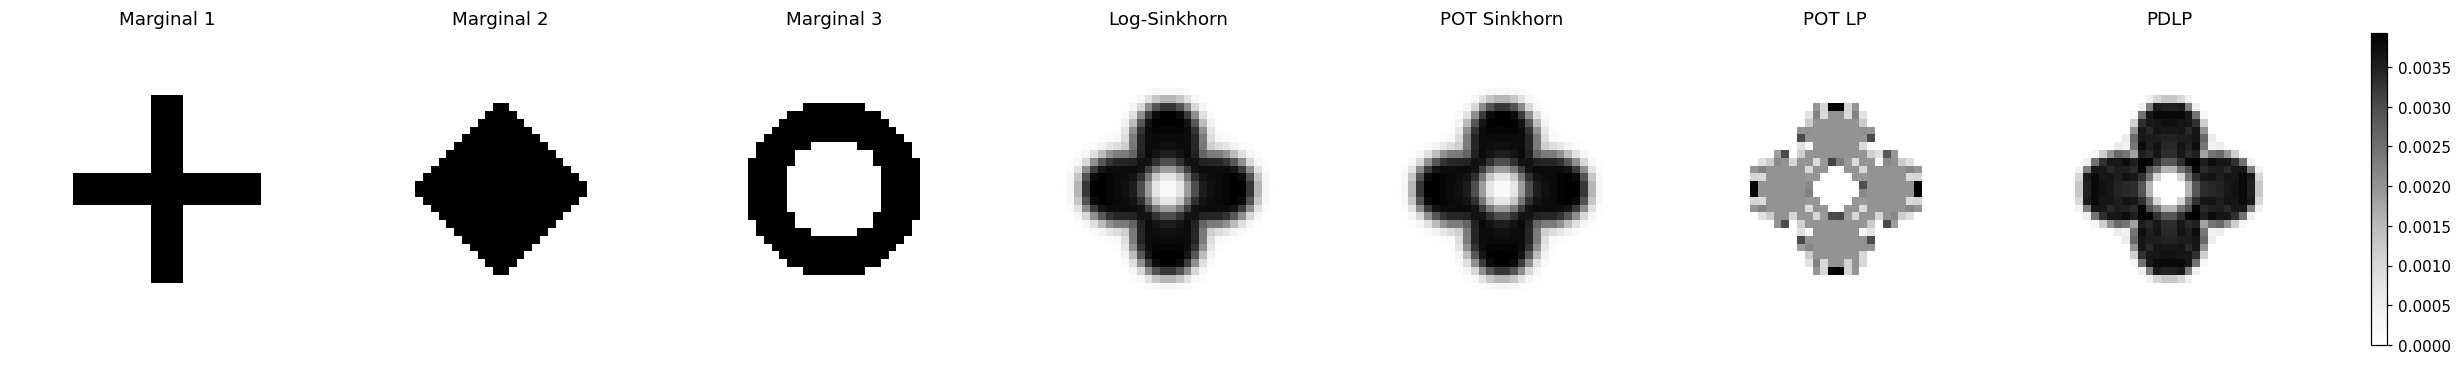

In [37]:
fields = measure_fields + [bary_sinkhorn_field, bary_sinkhorn_pot_field, bary_lp_field, bary_pdlp_field]
fields_titles = [
    'Marginal 1', 'Marginal 2', 'Marginal 3',
    'Log-Sinkhorn', 'POT Sinkhorn', 'POT LP', 'PDLP'
]

fig, plot_axes = plt.subplots(
    1,
    len(fields),
    figsize=(3.2 * len(fields), 3.2),
    constrained_layout=True,
)
if len(fields) == 1:
    plot_axes = [plot_axes]

im = None
for ax, field, title in zip(plot_axes, fields, fields_titles):
    im = ax.imshow(field.T, vmin=0.0)
    ax.set_title(title)
    ax.axis('off')

fig.colorbar(im, ax=plot_axes, fraction=0.03, pad=0.02)
plt.show()

---

## Examples on shapes from images

Here we load shapes from the `imgs/` folder as binary grids and normalize them.
The set `selected_measures` controls which images are used.
After stacking the shared support, we test Sinkhorn and PDLP on these image-based marginals.


In [46]:
img_dir = '../imgs'
img_names = sorted([
    name for name in os.listdir(img_dir)
    if name.lower().endswith(('.png', '.jpg', '.jpeg', '.webp'))
])

size = (74, 74)
all_measures = {
    name: load_image_as_binary_grid(
        os.path.join(img_dir, name),
        size=size,
        threshold=0.5,
        invert=True,
        normalize=True,
        axes_mode='normalized',
    )
    for name in img_names
}
selected_measures = {
    'cristo_redentor.jpg',
    'motherland_monument_kyiv.jpg',
    'pisa_tower.jpg',
}
selected_names = [name for name in img_names if name in selected_measures]

measures = [all_measures[name] for name in selected_names]
lambdas = np.ones(len(measures)) / len(measures)


In [47]:
print('Available image files:')
for name in img_names:
    print(' -', name)


Available image files:
 - chestnut_leaf_kyiv.webp
 - coliseum.webp
 - cristo_redentor.jpg
 - eiffel_tower.jpg
 - motherland_monument_kyiv.jpg
 - pau_de_acucar.png
 - pisa_tower.jpg
 - toronto_tower.jpg


In [48]:
support, w0 = measures[0].to_discrete(include_zeros=True)
meas_array = np.stack(
    [np.asarray(w0).reshape(-1)] +
    [np.asarray(m.to_discrete(include_zeros=True)[1]).reshape(-1) for m in measures[1:]],
    axis=0,
)

cost = cost_euclid_squared(support, support)

grid_shape = np.asarray(measures[0].weights_nd).shape
measure_fields = [np.asarray(m.weights_nd) for m in measures]


In [49]:
b_sinkhorn, info_sinkhorn = barycenter_sinkhorn(
    measures=meas_array,
    cost=cost,
    lambdas=lambdas,
    reg=1e-4,
    tol=1e-4,
    maxiter=400,
    return_diagnostics=True,
)

print(f"Sinkhorn iterations = {int(info_sinkhorn['iterations'])}")
print(f"Sinkhorn error = {float(info_sinkhorn['error'])}")

sinkhorn_field = np.asarray(b_sinkhorn).reshape(grid_shape)


Sinkhorn iterations = 400
Sinkhorn error = 0.06459027372899584


In [ ]:
marginals = [
    DiscreteMeasure(points=support, weights=meas_array[i], name=f'measure_{i+1}')
    for i in range(meas_array.shape[0])
]

solver = PDLPBarycenterSolver()
result_pdlp = solver.solve(
    marginals=marginals,
    costs=[cost],
    weights=lambdas,
    reg=1e-0,
    maxiter=2000,
    tol=1e-3,
)

b_pdlp = np.asarray(result_pdlp['barycenter'])
print(f"PDLP iterations = {result_pdlp['iterations']}")
print(f"PDLP error = {result_pdlp['error']}")

pdlp_field = np.asarray(b_pdlp).reshape(grid_shape)


PDLP iterations = 1663
PDLP error = 8.105369463827597e-05


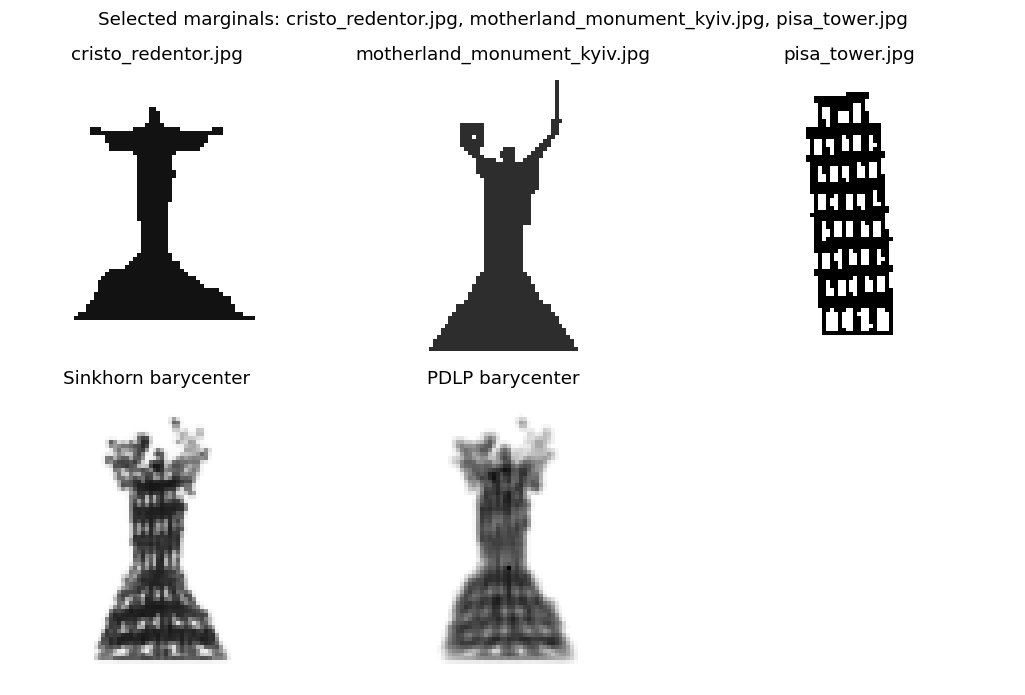

In [53]:
fields = measure_fields + [sinkhorn_field, pdlp_field]
titles = selected_names + ['Sinkhorn barycenter', 'PDLP barycenter']

vmax = max(np.max(f) for f in fields)
cols = 3
rows = int(np.ceil(len(fields) / cols))
fig, axes_plot = plt.subplots(rows, cols, figsize=(3.2 * cols, 3.2 * rows))
axes_plot = np.asarray(axes_plot).reshape(-1)

for ax, title, field in zip(axes_plot, titles, fields):
    im = ax.imshow(np.rot90(field, k=1).T, vmin=0.0, vmax=vmax)
    ax.set_title(title)
    ax.axis('off')

for ax in axes_plot[len(fields):]:
    ax.axis('off')

fig.suptitle('Selected marginals: ' + ', '.join(selected_names), fontsize=12)
fig.tight_layout()
plt.show()


---

## Additional: plotting barycenters on the interpolation grid

We sweep barycenter weights along an interpolation grid (simplex edge) and
plot the resulting barycenters inside the simplex, alongside the original marginals.


In [54]:
from matplotlib.offsetbox import OffsetImage, AnnotationBbox

In [56]:
# Load measures (same as in barycenter_icons copy.ipynb)
img_dir = '../imgs'
img_names = sorted([
    name for name in os.listdir(img_dir)
    if name.lower().endswith(('.png', '.jpg', '.jpeg', '.webp'))
])

# size = (128, 128)
# size = (192, 192)
size = (128, 128)
all_measures = {
    name: load_image_as_binary_grid(
        os.path.join(img_dir, name),
        size=size,
        threshold=0.2,
        invert=True,
        normalize=True,
        axes_mode='normalized',
    )
    for name in img_names
}

selected_measures = {
    'cristo_redentor.jpg',
    # 'chestnut_leaf_kyiv.webp',
    'eiffel_tower.jpg',
    # 'pau_de_acucar.png'
    'pisa_tower.jpg'
}
selected_names = [name for name in img_names if name in selected_measures]

measures = [all_measures[name] for name in selected_names]


In [58]:
# Lambda sweep over the simplex (grid)
step = 0.4  # smaller -> more barycenters
vals = np.arange(0.0, 1.0 + 1e-9, step)
lambda_grid = []
for l1 in vals:
    for l2 in vals:
        l3 = 1.0 - l1 - l2
        if l3 < -1e-9:
            continue
        if l3 < 0:
            l3 = 0.0
        lambda_grid.append(np.array([l1, l2, l3]))

print(f"Lambda grid size {len(lambda_grid)}")


Lambda grid size 6


In [ ]:
# Compute barycenters for each lambda
bary_fields = []
for lmb in lambda_grid:
    b, info = barycenter_sinkhorn(
        measures=meas_array,
        cost=cost,
        lambdas=lmb,
        reg=5e-3,
        tol=1e-4,
        maxiter=500,
        return_diagnostics=True,
    )
    field = np.asarray(b).reshape(grid_shape)
    bary_fields.append(field)


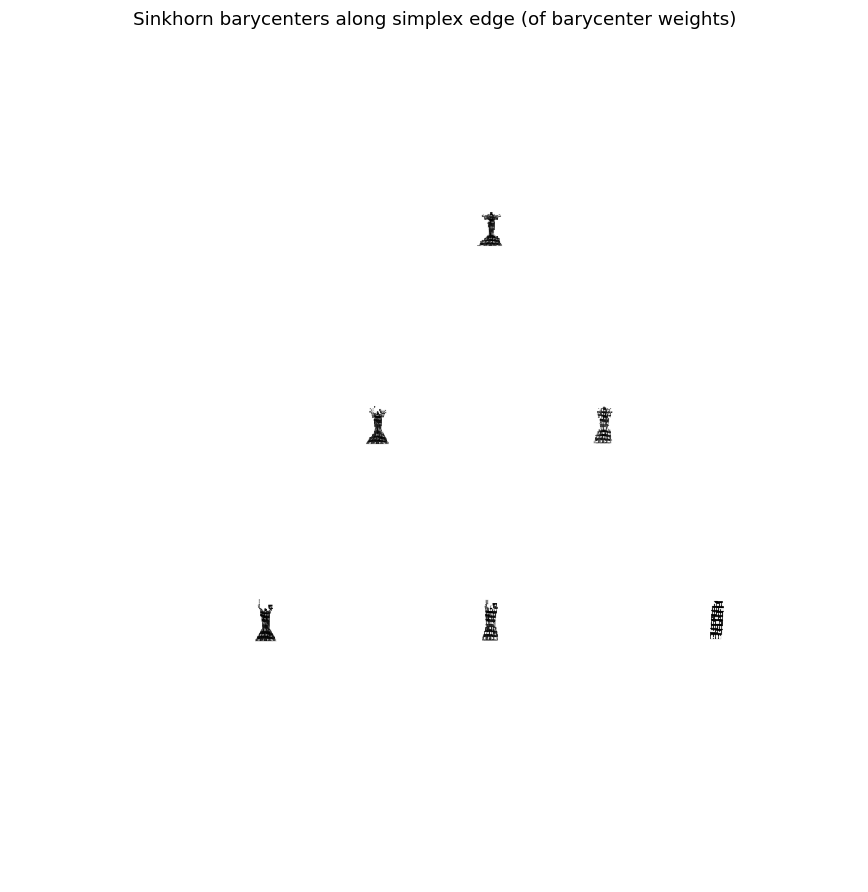

In [62]:
# Place marginals on a circle and barycenters inside
num_measures = len(measures)
angles = np.pi / 2 + 2.0 * np.pi * np.arange(num_measures) / num_measures
circle_pts = np.stack([np.cos(angles), np.sin(angles)], axis=1)

# Marginal fields
measure_fields = [np.asarray(m.weights_nd) for m in measures]

figsize = (10, 10)
fig, ax = plt.subplots(figsize=figsize)
ax.set_aspect('equal')
ax.axis('off')
ax.set_xlim(-1.3, 1.3)
ax.set_ylim(-1.3, 1.3)

# Plot barycenters at weighted positions
for lmb, field in zip(lambda_grid, bary_fields):
    pos = (lmb[:, None] * circle_pts).sum(axis=0)
    img = OffsetImage(field, cmap='Greys', zoom=0.40)
    ab = AnnotationBbox(img, pos, frameon=False)
    ax.add_artist(ab)

ax.set_title('Sinkhorn barycenters along simplex edge (of barycenter weights)')
plt.show()
